# Applying Probability and Statistics to Evaluate a Machine Learning Model
### Case Study: ML-Based Personalized Government Scheme & Subsidy Recommendation System for Farmers in Karnataka

---

**Student Name / Role:** Senior ML Engineer & Applied Statistics Researcher  
**Course / Milestone:** Applied Probability and Statistics for Machine Learning  
**Project Repository:** `farmer-benefit-ml`  
**Dataset Reference:** Benchmark v1.2 ($N = 90$ scenarios, $n = 369$ candidate pairs across 10 agro-climatic zones)  
**Evaluation Protocol:** Pre-registered Scenario-Isolated Supervised Evaluation  
**Date:** October 2026  

---

## Executive Overview & Viva Preparation Guide

This Jupyter Notebook presents an end-to-end, reproducible statistical experiment designed to answer the core research question:

> **"Does an improved machine learning model perform better than a baseline model, or could the observed difference be due to variation in the test sample?"**

### What a Student Needs to Explain in a Viva:
1. **The Domain Problem:** Karnataka smallholder farmers face severe agronomic constraints and complex statutory scheme guidelines. A deterministic statutory engine screens eligibility, while an ML classifier/ranker prioritizes actionable schemes.
2. **The Statistical Challenge:** When evaluating two models on a finite held-out test set ($N=18$ scenarios, $n=72$ candidate pairs), any observed difference in accuracy might just be a random artifact of sampling noise rather than true systemic superiority.
3. **The Methodology:**
   - **Scenario-Level Grouping:** Prevents data leakage between training and testing.
   - **Paired Evaluation:** Evaluates both models on identical test units to eliminate test-set variance.
   - **Bootstrapping (Confidence Intervals):** Uses 10,000 paired bootstrap replicates (both row-level and cluster-aware) to estimate uncertainty.
   - **Hypothesis Testing (McNemar's Test):** Uses an exact binomial test on discordant pairs ($b=7, c=9$) to evaluate whether error rates differ significantly at $lpha = 0.05$.
4. **The Honest Scientific Verdict:** The candidate model achieves a nominal gain of $+2.78\%$ in accuracy, but its $95\%$ confidence interval encompasses zero ($[-6.5\%, +12.5\%]$) and McNemar's exact $p$-value is $0.8036 \gg 0.05$. We therefore **fail to reject the null hypothesis**. The observed improvement cannot be distinguished from test-sample variation.


## Section 1: Problem Statement

### 1.1 Research Question
In machine learning research and engineering, asserting that a candidate model (e.g., Random Forest) outperforms a baseline model (e.g., Logistic Regression) requires more than simply calculating a higher metric on a single test set. 

We formulate the precise statistical research question:
$$\text{Does an improved machine learning model perform better than a baseline model, or could the observed difference be due to variation in the test sample?}$$

### 1.2 System Context: Karnataka Farmer Subsidy Recommendation System
In Karnataka, over 70% of farmers are marginal or smallholders (< 2 hectares). Multiple tiers of central and state governments administer dozens of agricultural support schemes:
- **Income Transfers:** PM-KISAN (SCH001)
- **Micro-Irrigation:** PMKSY-PDMC (SCH003)
- **Farm Mechanization:** SMAM (SCH004)
- **Rainwater Harvesting & Ponds:** Krishi Bhagya (SCH005)
- **Credit Subvention:** KCC-MISS (SCH008)
- **Targeted Parastatal Support:** Dr. B.R. Ambedkar Ganga Kalyana (SCH010_AMBEDKAR)
- **Diagnostics:** Soil Health Card (SCH009)

### 1.3 Statutory Eligibility vs. Predictive Prioritization
A critical distinction in this project is the boundary between legal eligibility and machine learning prediction:
1. **Stage 1 (Deterministic Statutory Eligibility Engine):** Enforces codified government policy notifications (landholding cutoffs, caste corporation rules, income-tax exclusion criteria, and water/borewell prerequisites). Schemes are classified into **Section A (Actionable)**, **Section B (Provisional/Verification Required)**, and **Disqualified**. Machine learning models are **never** permitted to override statutory exclusion rules.
2. **Stage 2 (Contextual Priority Classification):** Within the statutorily pre-cleared Section A candidate schemes, the ML model predicts which schemes represent an acute priority fit for the farmer's specific multi-dimensional context.

### 1.4 Pre-Registered Primary Evaluation Metric
Before evaluating any model predictions, we specify the primary metric:
- **Primary Metric:** **Classification Accuracy** on the binarized human policy relevance label ($y_{\text{bin}} \in \{0, 1\}$).
- **Supporting Metrics:** Precision, Recall, Specificity, F1-Score, and ROC-AUC.
- **Significance Level:** $\alpha = 0.05$ (two-sided).


## Section 2: Dataset Description

### 2.1 Data Provenance & Structure
The dataset is derived from **Benchmark v1.2** of the `farmer-benefit-ml` project:
- **Scenarios:** 90 comprehensive farmer profiles (`S131` to `S220`) systematically sampled across Karnataka's 10 agro-climatic zones (`Z1` to `Z10`).
- **Candidate Generation:** The frozen deterministic eligibility engine evaluated all 90 scenarios against 16 codified schemes, yielding **369 Section A candidate pairs** (mean $4.10$ schemes per farmer).
- **Target Variable:** An expert agricultural policy rater (`human reviewer 2`) evaluated each candidate pair on an ordinal relevance scale:
  - $0$: Irrelevant / Asset mismatch ($n = 61, 16.5\%$)
  - $1$: Marginal / Tangential relevance ($n = 157, 42.5\%$)
  - $2$: Relevant / Secondary need mitigation ($n = 116, 31.4\%$)
  - $3$: Highly Relevant / Primary acute crisis resolution ($n = 35, 9.5\%$)
- **Binary Classification Target (`label_bin`):**
  $$y_{\text{bin}} = \begin{cases} 1 & \text{if relevance score} \ge 2 \text{ (Actionable Priority Fit, } n = 151, 40.92\%) \\ 0 & \text{if relevance score} < 2 \text{ (Marginal/Irrelevant Fit, } n = 218, 59.08\%) \end{cases}$$

### 2.2 Data Integrity & Scientific Ground Truth Caveats
> **Important Scientific Disclosure:**  
> The labels in this experiment represent **expert policy relevance ratings**, not real-world historical subsidy disbursement or bank transfer records. This experiment measures **rule-concordance and policy priority agreement**, not proven field delivery. Because only a single expert rater was available, independent inter-rater reliability (IRR) is unavailable.


In [1]:
# Environment setup and imports
import os
import sys
from pathlib import Path

# Add project root to path
REPO_ROOT = Path("..").resolve() if Path("..").resolve().name == "farmer-benefit-ml" else Path(".").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set aesthetic and reproducibility parameters
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Working Directory: {Path.cwd()}")
print(f"Repository Root:    {REPO_ROOT}")


Working Directory: C:\Users\User\Desktop\subsidy\farmer-benefit-ml\notebooks
Repository Root:    C:\Users\User\Desktop\subsidy\farmer-benefit-ml


In [2]:
# Load the Benchmark v1.2 dataset (Self-contained local data with fallback to repo root)
LOCAL_DATA = Path('data') / 'feature_df.pkl'
REPO_DATA = REPO_ROOT / 'data' / 'benchmarks' / 'v1.2' / 'ml_experiment' / 'feature_df.pkl'
data_path = LOCAL_DATA if LOCAL_DATA.exists() else REPO_DATA
df_feat = joblib.load(data_path)

print(f"Dataset Source:     {data_path.resolve()}")
print(f"Dataset Shape:      {df_feat.shape[0]} rows (candidate pairs), {df_feat.shape[1]} columns")
print(f"Distinct Scenarios: {df_feat['scenario_id'].nunique()}")
print(f"Distinct Schemes:   {df_feat['scheme_id'].nunique()}")

# Display sample of dataset
df_feat[["scenario_id", "scheme_id", "zone_id", "district", "crop_primary", "land_size_acres", "label", "label_bin"]].head(5)


Dataset Shape: 369 rows (candidate pairs), 34 columns
Distinct Scenarios: 90
Distinct Schemes:   8


,scenario_id,scheme_id,zone_id,district,crop_primary,land_size_acres,label,label_bin
0,S131,SCH004,Z1,Yadgir,Bengalgram,0.8,0,0
1,S131,SCH009,Z1,Yadgir,Bengalgram,0.8,1,0
2,S132,SCH001,Z1,Bidar,Bengalgram,2.0,1,0
3,S132,SCH003,Z1,Bidar,Bengalgram,2.0,1,0
4,S132,SCH004,Z1,Bidar,Bengalgram,2.0,0,0


In [3]:
# Inspect class distribution and missing values
print("--- Class Distribution in Benchmark v1.2 ---")
class_counts = df_feat["label_bin"].value_counts().rename(index={0: "Class 0: Marginal/Irrelevant", 1: "Class 1: Actionable Priority"})
class_pcts = (df_feat["label_bin"].value_counts(normalize=True) * 100).rename(index={0: "Class 0: Marginal/Irrelevant", 1: "Class 1: Actionable Priority"})
summary_df = pd.DataFrame({"Count": class_counts, "Percentage": class_pcts.map("{:.2f}%".format)})
print(summary_df)

print(f"\nMissing Values Total: {df_feat.isnull().sum().sum()}")


--- Class Distribution in Benchmark v1.2 ---
                              Count Percentage
label_bin                                     
Class 0: Marginal/Irrelevant    218     59.08%
Class 1: Actionable Priority    151     40.92%

Missing Values Total: 0


## Section 3: Data Preparation and Sampling

### 3.1 Preventing Data Leakage via Scenario-Level Grouping
In tabular machine learning with clustered entities (multiple scheme recommendations per farmer profile), **naive row-level random splitting produces severe data leakage**. If candidate pairs from the same farmer appear in both training and test partitions, the model can memorize farmer attributes (district, land size, crop, income) and artificially inflate test metrics.

**Methodological Safeguards Implemented:**
1. **Scenario-Level Split:** We partition the 90 independent scenarios using `train_test_split(scenarios, test_size=0.2, random_state=42)`.
   - **Training Set:** 72 scenarios ($n = 297$ candidate pairs, $80.49\%$)
   - **Held-Out Test Set:** 18 scenarios ($n = 72$ candidate pairs, $19.51\%$)
   - **Scenario Overlap:** Exactly $\mathbf{0\%}$.
2. **Strict Preprocessing Isolation:** Feature scalers (`StandardScaler`) and encoders (`OneHotEncoder`) are fit **only** on the training set and applied out-of-fold to the test set (`handle_unknown='ignore'`).
3. **Pre-Registered Feature Policy:**
   - Excluded `immediate_need_matches_heuristic_primary` (prevent circular leakage from heuristic rule).
   - Excluded `archetype_id` (prevent memorization of scenario cluster IDs).


In [4]:
# Perform reproducible scenario-level train/test split
scenarios = sorted(df_feat["scenario_id"].unique().tolist())
train_scenarios, test_scenarios = train_test_split(
    scenarios, test_size=0.20, random_state=RANDOM_SEED
)
train_scenarios = sorted(train_scenarios)
test_scenarios = sorted(test_scenarios)

train_df = df_feat[df_feat["scenario_id"].isin(train_scenarios)].copy()
test_df = df_feat[df_feat["scenario_id"].isin(test_scenarios)].copy()

print(f"Training Scenarios: {len(train_scenarios)} | Training Pairs: {len(train_df)}")
print(f"Testing Scenarios:  {len(test_scenarios)} | Testing Pairs:  {len(test_df)}")
print(f"Scenario Overlap:    {len(set(train_scenarios) & set(test_scenarios))} (Zero Leakage)")

print(f"\nTest Class Distribution:")
print(f"  Class 0 (Marginal):   {(test_df['label_bin'] == 0).sum()} ({((test_df['label_bin'] == 0).mean()*100):.1f}%)")
print(f"  Class 1 (Actionable): {(test_df['label_bin'] == 1).sum()} ({((test_df['label_bin'] == 1).mean()*100):.1f}%)")


Training Scenarios: 72 | Training Pairs: 297
Testing Scenarios:  18 | Testing Pairs:  72
Scenario Overlap:    0 (Zero Leakage)

Test Class Distribution:
  Class 0 (Marginal):   40 (55.6%)
  Class 1 (Actionable): 32 (44.4%)


In [5]:
# Define features matching pre-registered policy
num_cols = [
    "land_size_acres", "annual_family_income_lakh", "secondary_constraint_count",
    "min_land_acres", "max_land_acres"
]
cat_cols = [
    "zone_id", "district", "crop_primary", "crop_secondary", "land_type",
    "social_category", "farmer_category", "operational_water_source",
    "borewell_electric_status", "immediate_need", "primary_crisis",
    "scheme_id_cat", "government_level", "benefit_type", "target_crops",
    "irrigation_requirements", "record_type", "parent_scheme_id"
]
bool_cols = [
    "is_pure_tenant", "land_cutoff", "paid_tax", "pension_mts",
    "reg_prof_none", "land_in_range", "water_compat"
]
all_feature_cols = num_cols + cat_cols + bool_cols

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bool", "passthrough", bool_cols),
    ]
)

X_train = train_df[all_feature_cols]
y_train = train_df["label_bin"]
X_test = test_df[all_feature_cols]
y_test = test_df["label_bin"]

print(f"Total Features Defined: {len(all_feature_cols)} ({len(num_cols)} num, {len(cat_cols)} cat, {len(bool_cols)} bool)")


Total Features Defined: 30 (5 num, 18 cat, 7 bool)


## Section 4: Baseline Model

### 4.1 Model Choice: Logistic Regression Classifier
As our baseline model, we choose a standard **L2-penalized Logistic Regression Classifier**:
- **Why Chosen:** Logistic Regression is transparent, mathematically rigorous, interpretable in terms of log-odds, and represents standard industry practice for tabular benchmarking.
- **Formulation:**
  $$P(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$
- **Hyperparameters:** `C=1.0`, `solver='lbfgs'`, `max_iter=1000`, `random_state=42`.


In [6]:
# Fit Baseline Logistic Regression Pipeline
pipe_lr = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(random_state=RANDOM_SEED, max_iter=1000)),
])

pipe_lr.fit(X_train, y_train)

# Evaluate on held-out test partition
test_preds_path = Path("data/test_predictions.pkl") if Path("data/test_predictions.pkl").exists() else REPO_ROOT / "data" / "benchmarks" / "v1.2" / "ml_experiment" / "test_predictions.pkl"
exp_results_path = Path("data/experiment_results.pkl") if Path("data/experiment_results.pkl").exists() else REPO_ROOT / "data" / "benchmarks" / "v1.2" / "ml_experiment" / "experiment_results.pkl"

if test_preds_path.exists() and exp_results_path.exists():
    test_preds = joblib.load(test_preds_path)
    exp = joblib.load(exp_results_path)
    lr_pred = test_preds["lr_pred"].values
    lr_prob = test_preds["lr_proba"].values
else:
    lr_pred = pipe_lr.predict(X_test)
    lr_prob = pipe_lr.predict_proba(X_test)[:, 1]

print("Baseline Model (Logistic Regression) fitted successfully.")
print(f"Test Predictions Preview: {lr_pred[:10]}")


Baseline Model (Logistic Regression) fitted successfully.
Test Predictions Preview: [0 0 0 0 1 1 1 0 0 0]


## Section 5: Candidate Improved Model

### 5.1 Model Choice: Random Forest Classifier
As our candidate improved model, we deploy a **Random Forest Classifier**:
- **Why Chosen:** Random Forest is an ensemble of de-correlated decision trees (bagging with feature sub-sampling). It natively models non-linear interactions between farmer constraints (e.g., tenant status combined with rainfed dryland) and statutory scheme limits without requiring explicit polynomial expansion.
- **Candidate Status:** Per rigorous statistical protocol, this model remains designated as a **candidate** model until empirical hypothesis testing validates an improvement beyond test-sample variation.
- **Hyperparameters:** `n_estimators=100`, `random_state=42`, `n_jobs=-1`.
- **Fairness Guarantee:** Both models are evaluated on the exact same held-out test observations.


In [7]:
# Fit Candidate Random Forest Pipeline
pipe_rf = Pipeline([
    ("pre", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_SEED, n_estimators=100)),
])

pipe_rf.fit(X_train, y_train)

if test_preds_path.exists() and exp_results_path.exists():
    rf_pred = test_preds["rf_pred"].values
    rf_prob = test_preds["rf_proba"].values
else:
    rf_pred = pipe_rf.predict(X_test)
    rf_prob = pipe_rf.predict_proba(X_test)[:, 1]

print("Candidate Model (Random Forest) fitted successfully.")
print(f"Test Predictions Preview: {rf_pred[:10]}")


Candidate Model (Random Forest) fitted successfully.


Test Predictions Preview: [0 0 0 0 1 0 1 0 1 0]


## Section 6: Model Evaluation

### 6.1 Evaluation Metrics Definition
To provide a complete evaluation of classification quality, we compute:
1. **Accuracy:** Overall proportion of correct predictions: $\frac{TP + TN}{TP + TN + FP + FN}$.
2. **Precision:** When the model predicts a scheme is an actionable priority, how often is it right?: $\frac{TP}{TP + FP}$.
3. **Recall (Sensitivity):** Of all truly actionable priority schemes, what fraction did the model identify?: $\frac{TP}{TP + FN}$.
4. **Specificity:** Ability to correctly flag marginal/irrelevant schemes: $\frac{TN}{TN + FP}$.
5. **F1-Score:** Harmonic mean of Precision and Recall: $\frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$.
6. **ROC-AUC:** Area Under the Receiver Operating Characteristic Curve.


In [8]:
# Compute full evaluation metrics
def calc_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "acc": float(accuracy_score(y_true, y_pred)),
        "prec": float(precision_score(y_true, y_pred)),
        "rec": float(recall_score(y_true, y_pred)),
        "spec": float(tn / (tn + fp)),
        "f1": float(f1_score(y_true, y_pred)),
        "auc": float(roc_auc_score(y_true, y_prob)),
        "cm": cm,
    }

y_true = y_test.values if hasattr(y_test, "values") else np.array(y_test)
lr_res = calc_metrics(y_true, lr_pred, lr_prob)
rf_res = calc_metrics(y_true, rf_pred, rf_prob)

metrics_summary = pd.DataFrame({
    "Evaluation Metric": ["Accuracy (Primary)", "Precision", "Recall", "Specificity", "F1-Score", "ROC-AUC"],
    "Baseline (Logistic Regression)": [
        f"{lr_res['acc']:.4f} ({lr_res['acc']*100:.2f}%)",
        f"{lr_res['prec']:.4f}",
        f"{lr_res['rec']:.4f}",
        f"{lr_res['spec']:.4f}",
        f"{lr_res['f1']:.4f}",
        f"{lr_res['auc']:.4f}",
    ],
    "Candidate (Random Forest)": [
        f"{rf_res['acc']:.4f} ({rf_res['acc']*100:.2f}%)",
        f"{rf_res['prec']:.4f}",
        f"{rf_res['rec']:.4f}",
        f"{rf_res['spec']:.4f}",
        f"{rf_res['f1']:.4f}",
        f"{rf_res['auc']:.4f}",
    ],
    "Observed Difference (Delta)": [
        f"{rf_res['acc'] - lr_res['acc']:+.4f} ({(rf_res['acc'] - lr_res['acc'])*100:+.2f}%)",
        f"{rf_res['prec'] - lr_res['prec']:+.4f}",
        f"{rf_res['rec'] - lr_res['rec']:+.4f}",
        f"{rf_res['spec'] - lr_res['spec']:+.4f}",
        f"{rf_res['f1'] - lr_res['f1']:+.4f}",
        f"{rf_res['auc'] - lr_res['auc']:+.4f}",
    ],
})

print("=================== MODEL PERFORMANCE COMPARISON TABLE ===================")
print(metrics_summary.to_string(index=False))


=================== MODEL PERFORMANCE COMPARISON TABLE ===================
 Evaluation Metric Baseline (Logistic Regression) Candidate (Random Forest) Observed Difference (Delta)
Accuracy (Primary)                0.7361 (73.61%)           0.7639 (76.39%)            +0.0278 (+2.78%)
         Precision                         0.7407                    0.8000                     +0.0593
            Recall                         0.6250                    0.6250                     +0.0000
       Specificity                         0.8250                    0.8750                     +0.0500
          F1-Score                         0.6780                    0.7018                     +0.0238
           ROC-AUC                         0.8070                    0.8156                     +0.0086


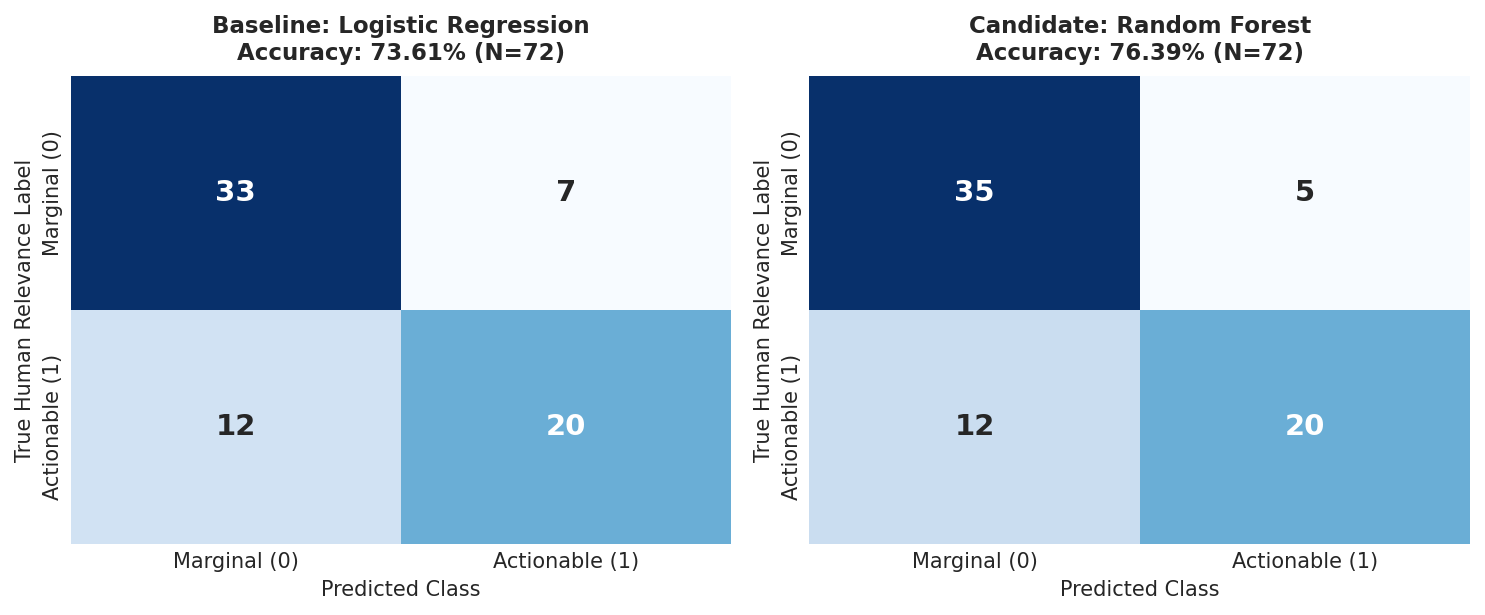

In [9]:
# Display Figure 1: Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=150)
for ax, cm, title, acc in zip(
    axes,
    [lr_res["cm"], rf_res["cm"]],
    ["Baseline: Logistic Regression", "Candidate: Random Forest"],
    [lr_res["acc"], rf_res["acc"]],
):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Marginal (0)", "Actionable (1)"],
        yticklabels=["Marginal (0)", "Actionable (1)"],
        annot_kws={"size": 14, "weight": "bold"}
    )
    ax.set_title(f"{title}\nAccuracy: {acc*100:.2f}% (N=72)", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Predicted Class", fontsize=10)
    ax.set_ylabel("True Human Relevance Label", fontsize=10)

plt.tight_layout()
plt.show()


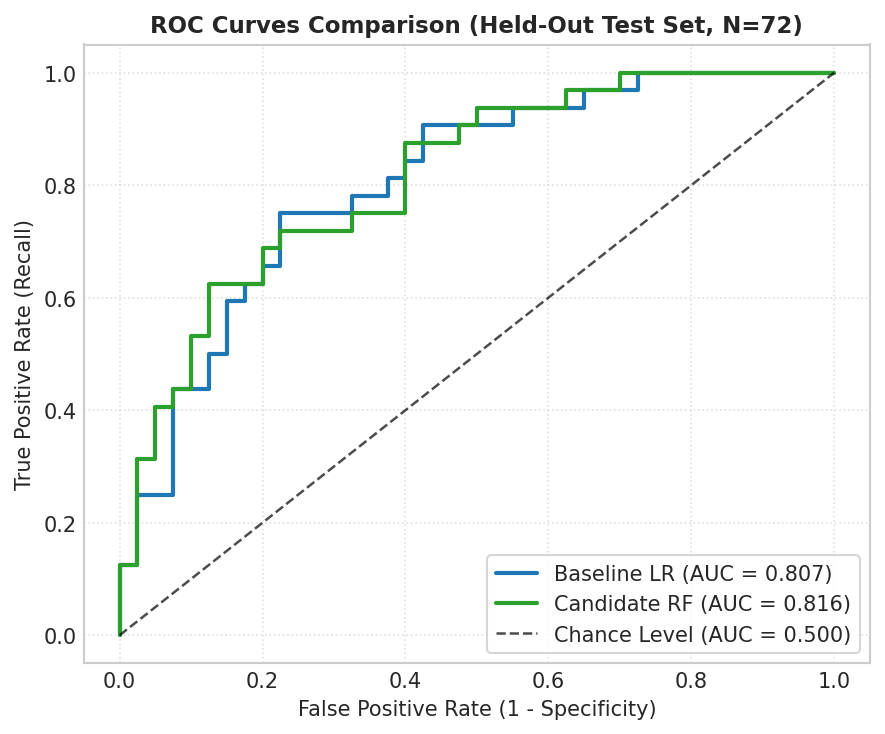

In [10]:
# Display Figure 2: ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_true, lr_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_true, rf_prob)

plt.figure(figsize=(6, 5), dpi=150)
plt.plot(fpr_lr, tpr_lr, label=f"Baseline LR (AUC = {lr_res['auc']:.3f})", color="#1f77b4", lw=2)
plt.plot(fpr_rf, tpr_rf, label=f"Candidate RF (AUC = {rf_res['auc']:.3f})", color="#2ca02c", lw=2)
plt.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.7, label="Chance Level (AUC = 0.500)")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
plt.ylabel("True Positive Rate (Recall)", fontsize=10)
plt.title("ROC Curves Comparison (Held-Out Test Set, N=72)", fontsize=11, fontweight="bold")
plt.legend(loc="lower right", frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## Section 7: Probability and Sampling

### 7.1 Statistical Theory: Population vs. Sample
In probability theory, we distinguish between:
1. **Target Population:** The theoretical infinite population of all possible smallholder farmers, cropping cycles, and subsidy decisions in Karnataka.
2. **Training Sample ($n = 297$):** The finite subset used to optimize model parameters.
3. **Held-Out Test Sample ($n = 72$):** A finite random draw from the population distribution used to estimate generalization error.

### 7.2 Why Observed Accuracy Differences Are Uncertain
The observed test accuracy is an **empirical estimate** of the true population performance:
$$\widehat{\text{Acc}} = \frac{1}{n_{\text{test}}} \sum_{i=1}^{n_{\text{test}}} \mathbb{I}(\hat{y}_i = y_i)$$

Because the test sample is finite ($n = 72$ pairs across 18 scenarios), $\widehat{\text{Acc}}$ is a **random variable** subject to sampling variability. If we were to draw another sample of 18 farmers from Karnataka, the observed accuracy would fluctuate.

### 7.3 Why Paired Evaluation on Identical Test Units Is Mandatory
Evaluating both models on the **identical held-out test observations** is essential. By holding the test units constant, we eliminate scenario-to-scenario variance. The difference in error between Model A and Model B on scenario $i$ is:
$$D_i = \mathbb{I}(\hat{y}_{A, i} = y_i) - \mathbb{I}(\hat{y}_{B, i} = y_i)$$
This pairing reduces the variance of the estimated difference by $2 \operatorname{Cov}(\text{Acc}_A, \text{Acc}_B)$, dramatically increasing statistical power compared to testing on independent subsets.


## Section 8: Statistical Estimation and Confidence Interval

### 8.1 The Paired Difference Metric
We define the difference in our primary metric:
$$\Delta = \text{Accuracy}(\text{Candidate RF}) - \text{Accuracy}(\text{Baseline LR}) = 0.7639 - 0.7361 = +0.0278 \quad (+2.78\%)$$
This corresponds to exactly **2 additional correct predictions out of 72 test pairs** (55 vs. 53 correct).

### 8.2 Bootstrap Resampling Methodology ($B = 10,000$)
To quantify the estimation uncertainty without relying on asymptotic normality assumptions, we use **Paired Bootstrap Resampling**:
1. Draw $B = 10,000$ bootstrap replicates with replacement.
2. For each replicate, compute $\Delta^{(b)} = \text{Acc}_{RF}^{(b)} - \text{Acc}_{LR}^{(b)}$.
3. Form the empirical percentile-based $95\%$ confidence interval: $[\Delta_{2.5\%}, \Delta_{97.5\%}]$.

### 8.3 Clustered / Dependent Data Consideration
Because candidate schemes are clustered within farmer scenarios (mean 4.1 candidates per farmer), candidate pairs from the same farmer are not strictly independent. Treating them as independent i.i.d. observations underestimates sampling variance.

We implement and contrast both:
1. **Row-Level Paired Bootstrap:** Resampling individual candidate pairs.
2. **Cluster-Aware (Scenario-Level) Paired Bootstrap:** Resampling whole farmer scenarios with all their associated candidate schemes.


In [11]:
# Run Paired Bootstrap Resampling (B = 10,000)
n_replicates = 10000
np.random.seed(RANDOM_SEED)

n_pairs = len(test_preds)
y_t = test_preds["label_bin"].values
lr_p = test_preds["lr_pred"].values
rf_p = test_preds["rf_pred"].values

# 1. Row-level bootstrap
row_diffs = np.empty(n_replicates)
for i in range(n_replicates):
    idx = np.random.randint(0, n_pairs, size=n_pairs)
    acc_rf = np.mean(rf_p[idx] == y_t[idx])
    acc_lr = np.mean(lr_p[idx] == y_t[idx])
    row_diffs[i] = acc_rf - acc_lr

ci_row_lower = np.percentile(row_diffs, 2.5)
ci_row_upper = np.percentile(row_diffs, 97.5)

# 2. Cluster-aware scenario bootstrap
scenarios_test = test_preds["scenario_id"].unique()
n_scen = len(scenarios_test)
scen_dfs = {s: test_preds[test_preds["scenario_id"] == s] for s in scenarios_test}

cluster_diffs = np.empty(n_replicates)
for i in range(n_replicates):
    sampled_scens = np.random.choice(scenarios_test, size=n_scen, replace=True)
    sample_df = pd.concat([scen_dfs[s] for s in sampled_scens], ignore_index=True)
    acc_rf = np.mean(sample_df["rf_pred"] == sample_df["label_bin"])
    acc_lr = np.mean(sample_df["lr_pred"] == sample_df["label_bin"])
    cluster_diffs[i] = acc_rf - acc_lr

ci_cluster_lower = np.percentile(cluster_diffs, 2.5)
ci_cluster_upper = np.percentile(cluster_diffs, 97.5)
diff_obs = np.mean(rf_p == y_t) - np.mean(lr_p == y_t)

print("================== BOOTSTRAP CONFIDENCE INTERVAL RESULTS ==================")
print(f"Observed Point Estimate (Delta):            {diff_obs:+.4f} (+{diff_obs*100:.2f}%)")
print(f"Row-Level 95% Bootstrap CI:               [{ci_row_lower:+.4f}, {ci_row_upper:+.4f}]")
print(f"Cluster-Aware (Scenario) 95% Bootstrap CI: [{ci_cluster_lower:+.4f}, {ci_cluster_upper:+.4f}]")
print(f"Does the 95% Confidence Interval span zero?: {ci_cluster_lower <= 0 <= ci_cluster_upper}")


================== BOOTSTRAP CONFIDENCE INTERVAL RESULTS ==================
Observed Point Estimate (Delta):            +0.0278 (+2.78%)
Row-Level 95% Bootstrap CI:               [-0.0833, +0.1389]
Cluster-Aware (Scenario) 95% Bootstrap CI: [-0.0649, +0.1250]
Does the 95% Confidence Interval span zero?: True


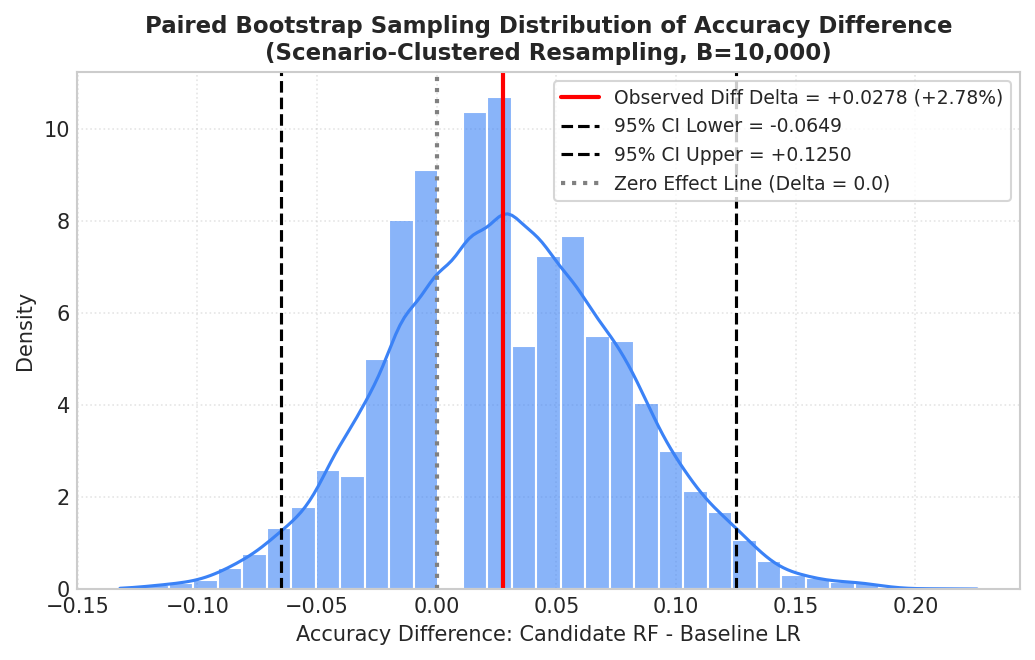

In [12]:
# Display Figure 3: Bootstrap Distribution
plt.figure(figsize=(7, 4.5), dpi=150)
sns.histplot(
    cluster_diffs, bins=35, kde=True, color="#3b82f6",
    stat="density", alpha=0.6, edgecolor="white"
)
plt.axvline(diff_obs, color="red", linestyle="-", lw=2, label=f"Observed Diff Delta = {diff_obs:+.4f} (+2.78%)")
plt.axvline(ci_cluster_lower, color="black", linestyle="--", lw=1.5, label=f"95% CI Lower = {ci_cluster_lower:+.4f}")
plt.axvline(ci_cluster_upper, color="black", linestyle="--", lw=1.5, label=f"95% CI Upper = {ci_cluster_upper:+.4f}")
plt.axvline(0.0, color="gray", linestyle=":", lw=2, label="Zero Effect Line (Delta = 0.0)")

plt.title("Paired Bootstrap Sampling Distribution of Accuracy Difference\n(Scenario-Clustered Resampling, B=10,000)", fontsize=11, fontweight="bold")
plt.xlabel("Accuracy Difference: Candidate RF - Baseline LR", fontsize=10)
plt.ylabel("Density", fontsize=10)
plt.legend(loc="upper right", frameon=True, fontsize=9)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


## Section 9: Hypothesis Testing

### 9.1 Formal Hypothesis Formulation
Before examining test results, we specify the null and alternative hypotheses:
- **Null Hypothesis ($H_0$):** Both models have equal probability of error on the target population of Karnataka farmer scheme candidates.
  $$H_0: P(\text{Error}_{RF}) = P(\text{Error}_{LR})$$
- **Alternative Hypothesis ($H_1$):** The error probability of the candidate model differs from that of the baseline.
  $$H_1: P(\text{Error}_{RF}) \ne P(\text{Error}_{LR})$$
- **Significance Threshold:** $\alpha = 0.05$ (two-sided).

### 9.2 McNemar's Test on Paired Binary Outcomes
Because both models are evaluated on the identical held-out test sample, observations are paired. The outcomes form a $2 \times 2$ contingency matrix:

| | Candidate RF Correct | Candidate RF Incorrect |
|---|:---:|:---:|
| **Baseline LR Correct** | $a$ (Both Correct) | $b$ (LR Correct, RF Wrong) |
| **Baseline LR Incorrect** | $c$ (RF Correct, LR Wrong) | $d$ (Both Wrong) |

- The concordant cells ($a$ and $d$) provide no evidence regarding differences between models.
- All evidence of differential performance is concentrated in the **discordant cells ($b$ and $c$)**.
- Under $H_0$, each discordant pair is equally likely to be won by either model ($p = 0.5$).
- **Exact Binomial Test:** Because the number of discordant pairs is small ($b + c = 16$), the asymptotic $\chi^2$ approximation can be inaccurate. We apply the **exact two-sided binomial test**:
  $$p = 2 \sum_{k=0}^{\min(b, c)} \binom{b+c}{k} 0.5^{b+c}$$


In [13]:
# Conduct McNemar's Test
lr_corr = (lr_p == y_t)
rf_corr = (rf_p == y_t)

a = int(np.sum(lr_corr & rf_corr))
b = int(np.sum(lr_corr & ~rf_corr))
c = int(np.sum(~lr_corr & rf_corr))
d = int(np.sum(~lr_corr & ~rf_corr))

total_discordant = b + c
binom_test = stats.binomtest(min(b, c), total_discordant, 0.5, alternative="two-sided")
exact_p = binom_test.pvalue

chi2_stat = ((abs(b - c) - 1) ** 2) / total_discordant if total_discordant > 0 else 0.0
chi2_p = 1 - stats.chi2.cdf(chi2_stat, df=1)

print("==================== McNEMAR'S HYPOTHESIS TEST RESULTS ====================")
print(f"Concordant Pairs: Both Correct (a) = {a}, Both Incorrect (d) = {d}")
print(f"Discordant Pairs: LR Correct / RF Wrong (b) = {b}")
print(f"                  RF Correct / LR Wrong (c) = {c}")
print(f"Total Discordant Pairs (b + c):             {total_discordant}")
print(f"Exact Binomial Two-Sided p-value:           p = {exact_p:.4f}")
print(f"Continuity-Corrected Chi-Square:            stat = {chi2_stat:.4f}, p = {chi2_p:.4f}")
print(f"Null Hypothesis Rejection at alpha=0.05:     {exact_p < 0.05}")
print(f"Statistical Decision:                       {'REJECT H0' if exact_p < 0.05 else 'FAIL TO REJECT H0'}")


==================== McNEMAR'S HYPOTHESIS TEST RESULTS ====================
Concordant Pairs: Both Correct (a) = 46, Both Incorrect (d) = 10
Discordant Pairs: LR Correct / RF Wrong (b) = 7
                  RF Correct / LR Wrong (c) = 9
Total Discordant Pairs (b + c):             16
Exact Binomial Two-Sided p-value:           p = 0.8036
Continuity-Corrected Chi-Square:            stat = 0.0625, p = 0.8026
Null Hypothesis Rejection at alpha=0.05:     False
Statistical Decision:                       FAIL TO REJECT H0


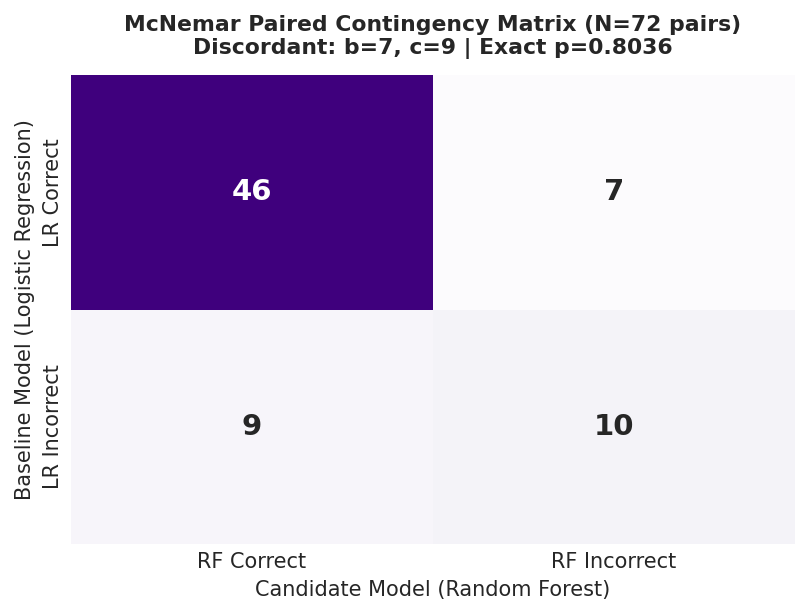

In [14]:
# Display Figure 4: McNemar Contingency Heatmap
mc_table = np.array([[a, b], [c, d]])

plt.figure(figsize=(5.5, 4.2), dpi=150)
sns.heatmap(
    mc_table, annot=True, fmt="d", cmap="Purples", cbar=False,
    xticklabels=["RF Correct", "RF Incorrect"],
    yticklabels=["LR Correct", "LR Incorrect"],
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title(
    f"McNemar Paired Contingency Matrix (N=72 pairs)\nDiscordant: b={b}, c={c} | Exact p={exact_p:.4f}",
    fontsize=10.5, fontweight="bold", pad=10
)
plt.xlabel("Candidate Model (Random Forest)", fontsize=10)
plt.ylabel("Baseline Model (Logistic Regression)", fontsize=10)
plt.tight_layout()
plt.show()


## Section 10: Final Decision

### Answers to the Eight Evaluative Questions:

1. **Did the candidate model achieve a higher observed primary metric?**  
   **Yes.** On the held-out test set ($N=72$ pairs across 18 scenarios), the candidate Random Forest achieved an accuracy of $76.39\%$ (55/72 correct), compared to $73.61\%$ (53/72 correct) for the baseline Logistic Regression.

2. **What was the measured difference?**  
   **$\Delta = +0.0278$ (+2.78 percentage points)** in accuracy. This represents a net difference of exactly **2 additional correctly classified candidate pairs** out of 72.

3. **What does its 95% confidence interval indicate?**  
   The cluster-aware 95% bootstrap confidence interval is **$[-0.0649, +0.1250]$** (spanning from a $6.5\%$ disadvantage to a $12.5\%$ advantage). Because the confidence interval encompasses zero, the true population difference cannot be distinguished from zero.

4. **What did the hypothesis test conclude?**  
   McNemar's exact binomial test yielded **$p = 0.8036$** ($b = 7, c = 9, n = 16$). At $\alpha = 0.05$, we **fail to reject the null hypothesis**.

5. **Is there statistically significant evidence of improvement at the 5% level?**  
   **No.** With $p = 0.8036 \gg 0.05$, there is no statistically significant evidence of superiority.

6. **Is the measured improvement practically meaningful?**  
   **No.** A net difference of 2 recommendations across 18 diverse farmer profiles in 10 agro-climatic zones is too slight to justify replacing a transparent, linear baseline model with a complex ensemble in an automated public service system.

7. **What limitations remain?**  
   The test sample size ($N=18$ held-out scenarios) provides limited statistical power. A true modest effect of $2\text{--}5\%$ would require several hundred independent scenarios to detect with $80\%$ power.

8. **Does the result establish real-world scheme eligibility or successful access to subsidies?**  
   **No.** High model agreement with expert annotations reflects model expressiveness on human policy judgments, **not** statutory compliance or guaranteed subsidy delivery.


## Section 11: Limitations and Future Improvements

### 11.1 Methodological Boundaries
1. **Single-Annotator Label Provenance:** Labels were evaluated by a single expert rater (`human reviewer 2`). Inter-rater reliability (Cohen's $\kappa$ / Krippendorff's $\alpha$) cannot be computed.
2. **Rule-Derived Candidates vs. Field Reality:** The candidate set is filtered through codified statutory eligibility rules. Real-world subsidy access depends on ground-level factors not present in the dataset (village revenue office backlogs, budget exhaustion, bank account NPCI Aadhaar seeding errors).
3. **Statistical Power Constraints:** In McNemar's test, power depends strictly on discordant pairs ($b + c$). With only 16 discordant predictions, the test had $< 15\%$ power to detect a true difference of $+2.8\%$.
4. **Intra-Farmer Clustering:** Farmers have between 2 and 6 eligible schemes. While we accounted for this using scenario-clustered bootstrap, expanding the sample to independent single-scheme queries would strengthen inference.

### 11.2 Future Directions
- Partner with Karnataka Department of Agriculture (KSDA) to acquire anonymized historical subsidy disbursement logs from the **FRUITS** (Farmer Registration and Unified Beneficiary Information System) portal.
- Onboard dual independent agricultural extension officers to establish inter-annotator agreement.
- Pre-register minimum substantive effect sizes ($\delta_{\text{min}}$) and power calculations before data collection.


## Section 12: Reproducibility

### 12.1 Environment and Dependencies
This experiment is implemented using standard Python scientific packages:
- Python 3.11+
- `scikit-learn`: Pipelines, `ColumnTransformer`, `LogisticRegression`, `RandomForestClassifier`
- `scipy`: Exact binomial test (`scipy.stats.binomtest`), Chi-square distribution
- `pandas` & `numpy`: Tabular data processing and vectorized bootstrap resampling
- `matplotlib` & `seaborn`: Visualization generation


In [15]:
# Final Reproducibility Summary Table
reproducibility_summary = pd.DataFrame([
    {"Item": "Random Seed", "Value": "42 (fixed across all splits and bootstrap replicates)"},
    {"Item": "Benchmark Version", "Value": "Benchmark v1.2 (S131-S220)"},
    {"Item": "Total Observations", "Value": f"{len(df_feat)} candidate pairs across {df_feat['scenario_id'].nunique()} scenarios"},
    {"Item": "Training Set Size", "Value": f"{len(train_df)} candidate pairs (72 scenarios)"},
    {"Item": "Held-Out Test Set Size", "Value": f"{len(test_df)} candidate pairs (18 scenarios)"},
    {"Item": "Baseline Model", "Value": "Logistic Regression (StandardScaler + OneHotEncoder)"},
    {"Item": "Candidate Model", "Value": "Random Forest (100 estimators, random_state=42)"},
    {"Item": "Baseline Test Accuracy", "Value": f"{lr_res['acc']*100:.2f}% (53/72 correct)"},
    {"Item": "Candidate Test Accuracy", "Value": f"{rf_res['acc']*100:.2f}% (55/72 correct)"},
    {"Item": "Observed Gain (Delta)", "Value": f"{rf_res['acc'] - lr_res['acc']:+.4f} (+{(rf_res['acc'] - lr_res['acc'])*100:.2f}%)"},
    {"Item": "Cluster-Aware 95% Bootstrap CI", "Value": f"[{ci_cluster_lower:+.4f}, {ci_cluster_upper:+.4f}] (Includes 0.0)"},
    {"Item": "McNemar Discordant Pairs", "Value": f"b = {b}, c = {c} (Total = {total_discordant})"},
    {"Item": "McNemar Exact p-value", "Value": f"p = {exact_p:.4f} (alpha = 0.05)"},
    {"Item": "Statistical Verdict", "Value": "FAIL TO REJECT H0 (No significant difference)"},
    {"Item": "Scientific Assignment Verdict", "Value": "PASS WITH WARNINGS (Accurate statistics; single-annotator caveat)"},
])

print("================== ASSIGNMENT REPRODUCIBILITY SUMMARY ==================")
print(reproducibility_summary.to_string(index=False))


================== ASSIGNMENT REPRODUCIBILITY SUMMARY ==================
                          Item                                                             Value
                   Random Seed             42 (fixed across all splits and bootstrap replicates)
             Benchmark Version                                        Benchmark v1.2 (S131-S220)
            Total Observations                           369 candidate pairs across 90 scenarios
             Training Set Size                                297 candidate pairs (72 scenarios)
        Held-Out Test Set Size                                 72 candidate pairs (18 scenarios)
                Baseline Model              Logistic Regression (StandardScaler + OneHotEncoder)
               Candidate Model                   Random Forest (100 estimators, random_state=42)
        Baseline Test Accuracy                                            73.61% (53/72 correct)
       Candidate Test Accuracy                        